<a href="https://colab.research.google.com/github/biiel19silva/MetalTracker/blob/main/Brasileir%C3%A3o.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Projeto: análise estatística de times do brasileirão (dados de 2003 - 2024)

**Objetivo:** Fazer a importação de um dataset via kaggle para se realizar a análise estatística de um time de futebol referente a serie A do campeonato brasileiro, desde exibir as partidas do time de um determinado ano até a geração de gráficos para se fazer uma análise de desempenho.



# Bibliotecas usadas:

- Kagglehub
- Shutil
- OS
- Pandas
- Matplotlib
- Seaborn

# **Etapa 1:** Importação de bibliotecas; instalação do kagglehub; download, manipulação e leitura do dataset

In [ ]:
!pip install kagglehub

In [ ]:
import kagglehub, shutil, os, pandas as pd, matplotlib.pyplot as plt, seaborn as sns

path = kagglehub.dataset_download("adaoduque/campeonato-brasileiro-de-futebol")

print("Path to dataset files:", path)

100%|██████████| 657k/657k [00:00<00:00, 96.0MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/adaoduque/campeonato-brasileiro-de-futebol/versions/16


In [ ]:
src = os.path.join(path, "campeonato-brasileiro-full.csv")
dst = "/content/campeonato-brasileiro-full.csv"
shutil.copy(src, dst)
print("Copiado para:", dst, os.path.exists(dst))

Copiado para: /content/campeonato-brasileiro-full.csv True


In [ ]:
# Load the dataset
try:
    df = pd.read_csv('/content/campeonato-brasileiro-full.csv')
except FileNotFoundError:
    print("Erro: O arquivo '/content/campeonato-brasileiro-full.csv' não foi encontrado.")
    exit()

# **Etapa 2:** Teste do dataset fazendo uma análise simples e filtragem condicional, caso o usuário deseje

In [ ]:
# Display the first 5 rows of the DataFrame
print("Primeiras 5 linhas do dataset:")
display(df.head())

# Display statistical summary of the DataFrame
print("\nResumo estatístico do dataset:")
display(df.describe())

# Print the column names
print("\nColunas do dataset:")
print(df.columns)

# Count missing values in each column
print("\nContagem de valores ausentes por coluna:")
display(df.isna().sum())

Primeiras 5 linhas do dataset:


,ID,rodata,data,hora,mandante,visitante,formacao_mandante,formacao_visitante,tecnico_mandante,tecnico_visitante,vencedor,arena,mandante_Placar,visitante_Placar,mandante_Estado,visitante_Estado
0,1,1,29/03/2003,16:00,Guarani,Vasco,NaN,NaN,NaN,NaN,Guarani,Brinco de Ouro,4,2,SP,RJ
1,2,1,29/03/2003,16:00,Athletico-PR,Gremio,NaN,NaN,NaN,NaN,Athletico-PR,Arena da Baixada,2,0,PR,RS
2,3,1,30/03/2003,16:00,Flamengo,Coritiba,NaN,NaN,NaN,NaN,-,Maracanã,1,1,RJ,PR
3,4,1,30/03/2003,16:00,Goias,Paysandu,NaN,NaN,NaN,NaN,-,Serra Dourada,2,2,GO,PA
4,5,1,30/03/2003,16:00,Internacional,Ponte Preta,NaN,NaN,NaN,NaN,-,Beira Rio,1,1,RS,SP



Resumo estatístico do dataset:


,ID,rodata,mandante_Placar,visitante_Placar
count,8785.000000,8785.000000,8785.000000,8785.000000
mean,4393.000000,20.105862,1.535572,1.027319
std,2536.155391,11.425072,1.224891,1.025375
min,1.000000,1.000000,0.000000,0.000000
25%,2197.000000,10.000000,1.000000,0.000000
50%,4393.000000,20.000000,1.000000,1.000000
75%,6589.000000,30.000000,2.000000,2.000000
max,8785.000000,46.000000,7.000000,7.000000



Colunas do dataset:
Index(['ID', 'rodata', 'data', 'hora', 'mandante', 'visitante',
       'formacao_mandante', 'formacao_visitante', 'tecnico_mandante',
       'tecnico_visitante', 'vencedor', 'arena', 'mandante_Placar',
       'visitante_Placar', 'mandante_Estado', 'visitante_Estado'],
      dtype='object')

Contagem de valores ausentes por coluna:


,0
ID,0
rodata,0
data,0
hora,0
mandante,0
visitante,0
formacao_mandante,4975
formacao_visitante,4975
tecnico_mandante,4610
tecnico_visitante,4610


In [ ]:
if 'df' in locals():
    # Get columns with missing values
    cols_with_missing = df.columns[df.isna().any()].tolist()

    if cols_with_missing:
        print(f"As seguintes colunas possuem valores ausentes: {', '.join(cols_with_missing)}")
        user_input = input("Deseja excluir essas colunas? (sim/não): ").lower()

        if user_input == 'sim':
            df = df.dropna(axis=1)
            print("Colunas com valores ausentes excluídas.")
            # Display the updated info after dropping columns
            print("\nInformações do dataset após a exclusão de colunas:")
            display(df.head())
            print("\nContagem de valores ausentes por coluna após a exclusão:")
            display(df.isna().sum())
        else:
            print("Dataset original mantido (colunas com valores ausentes não foram excluídas).")
    else:
        print("Não há colunas com valores ausentes no dataset.")
else:
    print("Erro: O DataFrame 'df' não foi encontrado. Certifique-se de que a célula de carregamento de dados foi executada.")

As seguintes colunas possuem valores ausentes: formacao_mandante, formacao_visitante, tecnico_mandante, tecnico_visitante
Deseja excluir essas colunas? (sim/não): sim
Colunas com valores ausentes excluídas.

Informações do dataset após a exclusão de colunas:


,ID,rodata,data,hora,mandante,visitante,vencedor,arena,mandante_Placar,visitante_Placar,mandante_Estado,visitante_Estado
0,1,1,29/03/2003,16:00,Guarani,Vasco,Guarani,Brinco de Ouro,4,2,SP,RJ
1,2,1,29/03/2003,16:00,Athletico-PR,Gremio,Athletico-PR,Arena da Baixada,2,0,PR,RS
2,3,1,30/03/2003,16:00,Flamengo,Coritiba,-,Maracanã,1,1,RJ,PR
3,4,1,30/03/2003,16:00,Goias,Paysandu,-,Serra Dourada,2,2,GO,PA
4,5,1,30/03/2003,16:00,Internacional,Ponte Preta,-,Beira Rio,1,1,RS,SP



Contagem de valores ausentes por coluna após a exclusão:


,0
ID,0
rodata,0
data,0
hora,0
mandante,0
visitante,0
vencedor,0
arena,0
mandante_Placar,0
visitante_Placar,0


# **Etapa 3:** Seleção de dados de um time em um determinado ano e exibição de suas partidas

In [ ]:
# Pedir ao usuário para selecionar o time para análise
team_name_df = input("Digite o nome do time que você deseja analisar: ")

# O nome do time selecionado está agora armazenado na variável 'team_name' para uso posterior.
print(f"Você selecionou o time: {team_name_df}")

# Como não há uma coluna 'Team', não filtraremos o DataFrame neste momento.
# Você pode usar a variável 'team_name' em células posteriores para filtrar ou analisar os dados
# se houver uma coluna correspondente no DataFrame ou se você precisar processar o nome do time de outra forma.

Digite o nome do time que você deseja analisar: sao paulo
Você selecionou o time: sao paulo


In [ ]:
# Converter a coluna 'data' para datetime para extrair o ano
df['data'] = pd.to_datetime(df['data'], format='%d/%m/%Y', errors='coerce')

# Obter os anos únicos disponíveis no DataFrame
available_years = df['data'].dt.year.dropna().unique()
available_years.sort()

if available_years.size == 0:
    print("Não foi possível extrair anos do dataset.")
else:
    print(f"Anos disponíveis no dataset: {', '.join(map(str, available_years))}")

    while True:
        try:
            selected_year_str = input(f"Digite o ano que você deseja analisar (entre {available_years.min()} e {available_years.max()}): ")
            selected_year = int(selected_year_str)
            if selected_year in available_years:
                break
            else:
                print("Ano inválido. Por favor, digite um ano que esteja na lista de anos disponíveis.")
        except ValueError:
            print("Entrada inválida. Por favor, digite um número para o ano.")

    # Filtrar as partidas do time selecionado pelo ano escolhido
    # Certifique-se de que 'team_name_df' foi criado na célula anterior
    if 'team_name_df' in locals() and team_name_df: # Check if the string is not empty
        # Filter the original DataFrame 'df', making team name comparison case-insensitive
        selected_year_team_df = df[
            ((df['mandante'].str.lower() == team_name_df.lower()) | (df['visitante'].str.lower() == team_name_df.lower())) &
            (df['data'].dt.year == selected_year)
        ]

        if selected_year_team_df.empty:
            print(f"Nenhuma partida encontrada para o time '{team_name_df}' no ano de {selected_year}.")
        else:
            print(f"Partidas do time '{team_name_df}' no ano de {selected_year}:")
            # Ordenar o DataFrame pela coluna 'rodata' (rodada) em ordem crescente
            selected_year_team_df_sorted = selected_year_team_df.sort_values(by='rodata')
            # Faz um display total das partidas desse ano em ordem crescente de rodada
            display(selected_year_team_df_sorted)
    else:
        print("Por favor, execute a célula anterior para selecionar o time primeiro.")

Anos disponíveis no dataset: 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024
Digite o ano que você deseja analisar (entre 2003 e 2024): 2015
Partidas do time 'sao paulo' no ano de 2015:


,ID,rodata,data,hora,mandante,visitante,vencedor,arena,mandante_Placar,visitante_Placar,mandante_Estado,visitante_Estado
4993,4992,1,2015-05-10,16:02,Sao Paulo,Flamengo,Sao Paulo,Morumbi,2,1,SP,RJ
5005,5005,2,2015-05-17,18:33,Ponte Preta,Sao Paulo,Ponte Preta,Moisés Lucarelli,1,0,SP,SP
5007,5007,3,2015-05-23,18:33,Sao Paulo,Joinville,Sao Paulo,Morumbi,3,0,SP,SC
5022,5024,4,2015-05-31,16:01,Internacional,Sao Paulo,-,Estádio José Pinheiro Borda,0,0,RS,SP
5029,5030,5,2015-06-03,21:02,Sao Paulo,Santos,Sao Paulo,Morumbi,3,2,SP,SP
5041,5042,6,2015-06-06,22:01,Sao Paulo,Gremio,Sao Paulo,Morumbi,2,0,SP,RS
5048,5049,7,2015-06-13,16:32,Chapecoense,Sao Paulo,Sao Paulo,Arena Condá,0,1,SC,SP
5063,5065,8,2015-06-21,16:00,Sao Paulo,Avai,-,Morumbi,1,1,SP,SC
5070,5071,9,2015-06-28,15:59,Palmeiras,Sao Paulo,Palmeiras,Allianz Parque,4,0,SP,SP
5082,5083,10,2015-07-01,22:01,Athletico-PR,Sao Paulo,Athletico-PR,Estádio Joaquim Américo Guimarães,2,1,PR,SP


# **Etapa 4:** Exibição do número de partidas, vitórias, derrotas e empates

In [ ]:
# Check if the DataFrame with selected year and team data exists
if 'selected_year_team_df_sorted' in locals() and not selected_year_team_df_sorted.empty:
    # Calculate wins, draws, and losses more efficiently using value_counts()
    # Make the comparison case-insensitive for counting wins
    outcome_counts = selected_year_team_df_sorted['vencedor'].str.lower().value_counts()

    # Get the count for the selected team (wins), using the lowercase team name
    wins = outcome_counts.get(team_name_df.lower(), 0)

    # Get the count for draws (draws are represented by '-')
    draws = outcome_counts.get('-', 0)

    # Calculate losses (total games - wins - draws)
    total_games = selected_year_team_df_sorted.shape[0]
    losses = total_games - wins - draws

    # Display the results
    print(f"Resultados do {team_name_df} em {selected_year}:")
    print(f"Total de Partidas: {total_games}")
    print(f"Vitórias: {wins}")
    print(f"Empates: {draws}")
    print(f"Derrotas: {losses}")
else:
    print("Erro: O DataFrame com as partidas do time e ano selecionados não foi encontrado ou está vazio. Por favor, execute a célula anterior para selecionar o time e o ano.")

Resultados do sao paulo em 2015:
Total de Partidas: 38
Vitórias: 18
Empates: 8
Derrotas: 12


# **Etapa 5:** visualização de um histórico ao decorrer dos anos do desempenho do time selecionado, organização dos dados em um dataframe e visualização condicional de desempenho a partir de um gráfico

In [ ]:
# Create an empty dictionary to store the results by year
team_results_by_year = {}

# Get the list of unique years available in the DataFrame 'df'
available_years = df['data'].dt.year.dropna().unique()
available_years.sort()

# Iterate over each available year
for year in available_years:
    # Filter the DataFrame for the selected team and the current year (case-insensitive)
    yearly_team_df = df[
        ((df['mandante'].str.lower() == team_name_df.lower()) | (df['visitante'].str.lower() == team_name_df.lower())) &
        (df['data'].dt.year == year)
    ]

    # Calculate the number of wins, draws, and losses for the team in this year (case-insensitive comparison for winner)
    yearly_wins = yearly_team_df[yearly_team_df['vencedor'].str.lower() == team_name_df.lower()].shape[0]
    yearly_draws = yearly_team_df[yearly_team_df['vencedor'] == '-'].shape[0]
    yearly_losses = yearly_team_df.shape[0] - yearly_wins - yearly_draws # Calculate losses based on total games

    # Store the results in the dictionary
    team_results_by_year[year] = {
        'vitorias': yearly_wins,
        'empates': yearly_draws,
        'derrotas': yearly_losses
    }

# Display the calculated results by year
print(f"Resultados do {team_name_df} por ano:")
for year, results in team_results_by_year.items():
    print(f"Ano {year}: Vitórias={results['vitorias']}, Empates={results['empates']}, Derrotas={results['derrotas']}")

Resultados do sao paulo por ano:
Ano 2003: Vitórias=22, Empates=12, Derrotas=12
Ano 2004: Vitórias=24, Empates=10, Derrotas=12
Ano 2005: Vitórias=16, Empates=10, Derrotas=16
Ano 2006: Vitórias=22, Empates=12, Derrotas=4
Ano 2007: Vitórias=23, Empates=8, Derrotas=7
Ano 2008: Vitórias=21, Empates=12, Derrotas=5
Ano 2009: Vitórias=18, Empates=11, Derrotas=9
Ano 2010: Vitórias=15, Empates=10, Derrotas=13
Ano 2011: Vitórias=16, Empates=11, Derrotas=11
Ano 2012: Vitórias=20, Empates=6, Derrotas=12
Ano 2013: Vitórias=14, Empates=8, Derrotas=16
Ano 2014: Vitórias=20, Empates=10, Derrotas=8
Ano 2015: Vitórias=18, Empates=8, Derrotas=12
Ano 2016: Vitórias=14, Empates=10, Derrotas=14
Ano 2017: Vitórias=13, Empates=11, Derrotas=14
Ano 2018: Vitórias=16, Empates=15, Derrotas=7
Ano 2019: Vitórias=17, Empates=12, Derrotas=9
Ano 2020: Vitórias=16, Empates=8, Derrotas=3
Ano 2021: Vitórias=13, Empates=19, Derrotas=17
Ano 2022: Vitórias=13, Empates=15, Derrotas=10
Ano 2023: Vitórias=14, Empates=11, Derro

In [ ]:
# Create a DataFrame from the team_results_by_year dictionary
yearly_results_df = pd.DataFrame.from_dict(team_results_by_year, orient='index')

# Rename columns for clarity
yearly_results_df.columns = ['vitorias', 'empates', 'derrotas']

# Set the index name to 'ano'
yearly_results_df.index.name = 'ano'

# Display the created DataFrame showing all years
#print("\nDataFrame com resultados por ano (todos os anos disponíveis):")
#display(yearly_results_df)

Os gráficos estão disponíveis para serem exibidos. Qual estatística você gostaria de visualizar? (vitórias, empates, derrotas)
derrotas


/tmp/ipython-input-2957117132.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=yearly_results_df.index, y=yearly_results_df[result_to_visualize], palette='viridis')


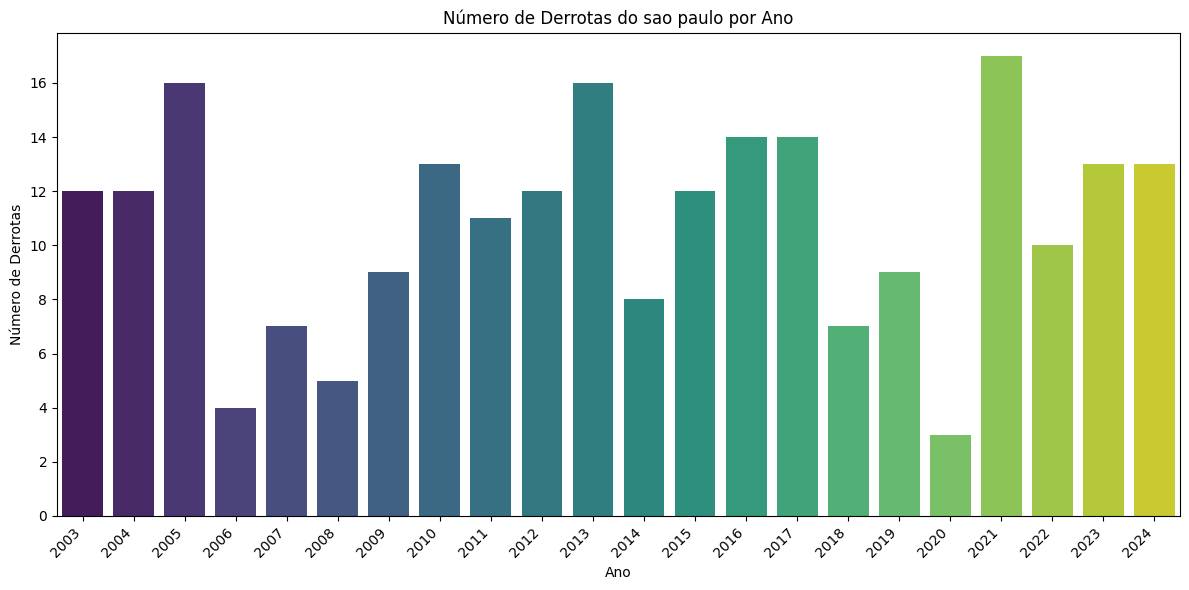

None

In [ ]:
# Check if the yearly_results_df DataFrame exists and is not empty
if 'yearly_results_df' in locals() and not yearly_results_df.empty:
    print("Os gráficos estão disponíveis para serem exibidos. Qual estatística você gostaria de visualizar? (vitórias, empates, derrotas)")

    # Get user input for the desired result to visualize
    result_to_visualize = input().lower()

    # Check if the result_to_visualize is valid
    valid_results = ['vitorias', 'vitórias', 'empates', 'derrotas']
    if result_to_visualize in valid_results:
        # Create the bar plot
        plt.figure(figsize=(12, 6)) # Adjust figure size for better readability
        sns.barplot(x=yearly_results_df.index, y=yearly_results_df[result_to_visualize], palette='viridis')

        # Set plot title and labels
        plt.title(f"Número de {result_to_visualize.capitalize()} do {team_name_df} por Ano")
        plt.xlabel("Ano")
        plt.ylabel(f"Número de {result_to_visualize.capitalize()}")

        # Rotate x-axis labels for better readability, especially with many years
        plt.xticks(rotation=45, ha='right')

        # Ensure layout is tight to prevent labels overlapping
        plt.tight_layout()

        # Display the plot
        display(plt.show())
    else:
        print(f"Resultado '{result_to_visualize}' inválido. Por favor, escolha entre: {', '.join(valid_results)}")
else:
    print("Erro: O DataFrame com os resultados por ano não foi encontrado ou está vazio. Por favor, execute as células anteriores para calcular os resultados por ano.")